# Ramen on CIFAR-10-C: evaluation and failure analysis

Runs **Ramen** and a **NoAdapt** baseline (zero-shot CLIP) on exactly the same test stream, then breaks down where Ramen helps and where it fails.
The code lives in `ramen_analysis.py` (`CIFAR10CExperiment`). Results are cached in `results/`, so you can re-run the plot cells without re-running the models.

In [1]:
%load_ext autoreload
%autoreload 2

import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '1')  # pick a free GPU; must be set before torch is imported

from ramen_analysis import CIFAR10CExperiment

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
exp = CIFAR10CExperiment(
    model='clip_vitbase32',
    tta_mode='mixed',      # 'mixed': one shuffled stream over all corruptions | 'single': each corruption separately, reset between
    batch_size=100,
    n_per_domain=None,     # None = whole dataset (10k images per corruption); e.g. 1000 for a quick run
    seed=0,
).load()

CIFAR10C: 15 corruptions x 10000 images, 10 classes, model=clip_vitbase32, mode=mixed


In [3]:
acc = exp.evaluate()   # pass use_cache=False to force a re-run
acc

NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_NoAdapt.pkl
Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_Ramen.pkl


,NoAdapt,Ramen,delta
gaussian_noise,38.66,60.84,22.18
shot_noise,42.59,63.14,20.55
impulse_noise,42.75,56.27,13.52
defocus_blur,72.61,77.12,4.51
glass_blur,43.91,64.01,20.10
motion_blur,66.68,77.55,10.87
zoom_blur,71.69,79.27,7.58
snow,73.78,80.65,6.87
frost,75.69,80.16,4.47
fog,68.85,77.93,9.08


## 1. Which corruptions does Ramen struggle on?
Orange = NoAdapt, blue = Ramen, so the line between them is what adaptation changes. Corruptions are sorted with Ramen's worst at the top. **Bold** numbers on the right are corruptions where Ramen does *worse* than doing nothing.

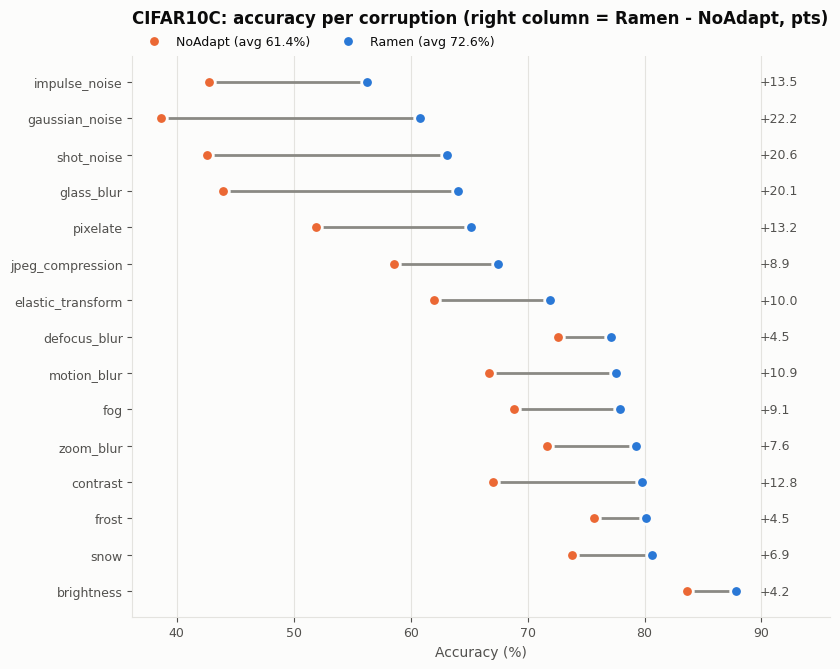

In [4]:
exp.plot_domain_accuracy();

## 2. Per-sample flips
The aggregate gain hides two opposing effects. Blue = samples Ramen **fixed** (NoAdapt wrong, Ramen right). Red = samples Ramen **broke** (NoAdapt right, Ramen wrong). A large red bar means harmful adaptation, even when the net gain is positive.

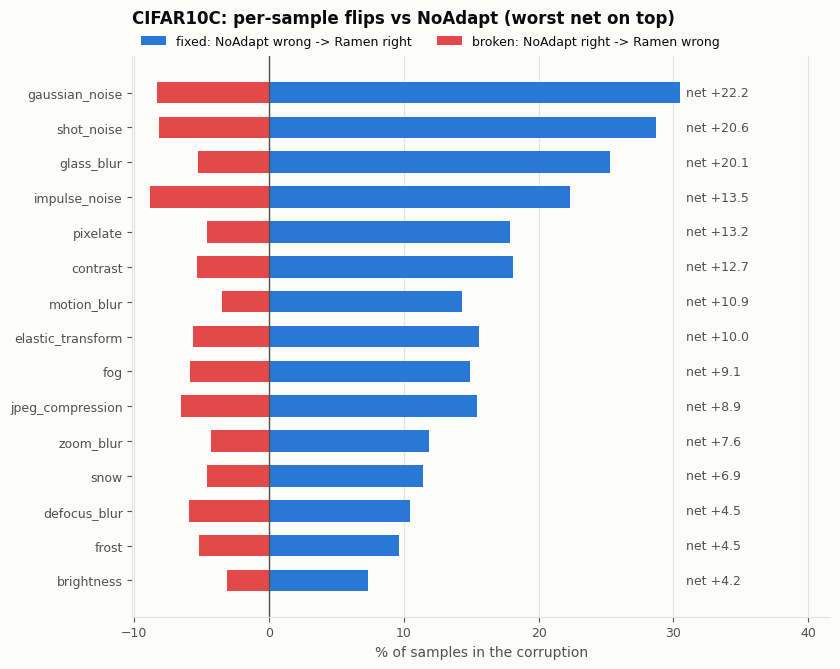

In [5]:
exp.plot_flips();

## 3. Which classes, under which corruptions?
Ramen − NoAdapt accuracy for each class and corruption. Red cells show where adaptation hurts. Rows are sorted with the worst at the top. The second heatmap shows Ramen's absolute accuracy.

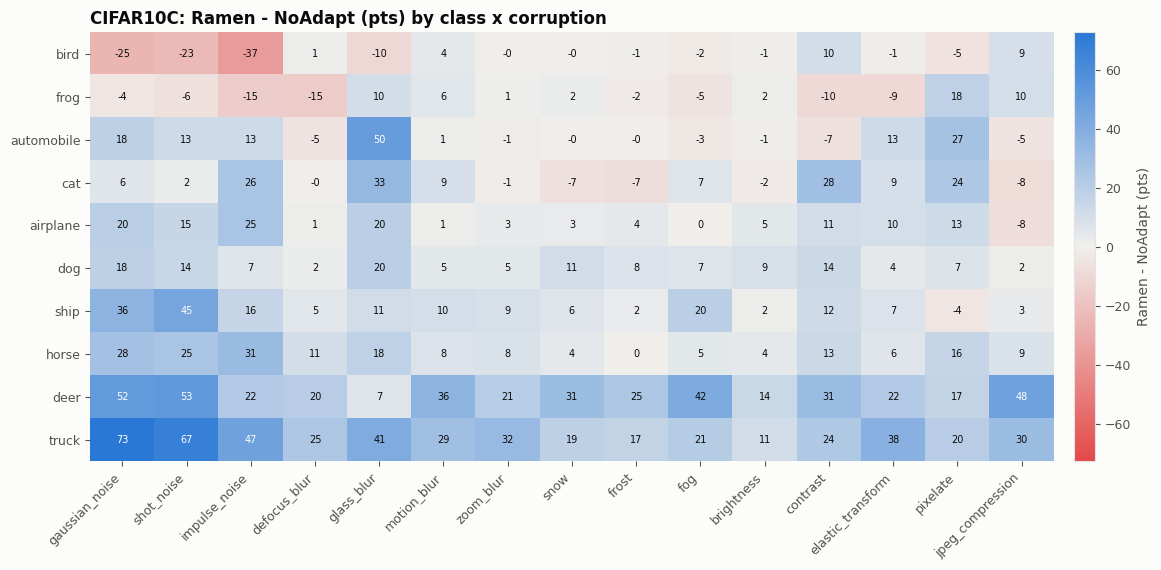

In [6]:
exp.plot_class_heatmap('delta');

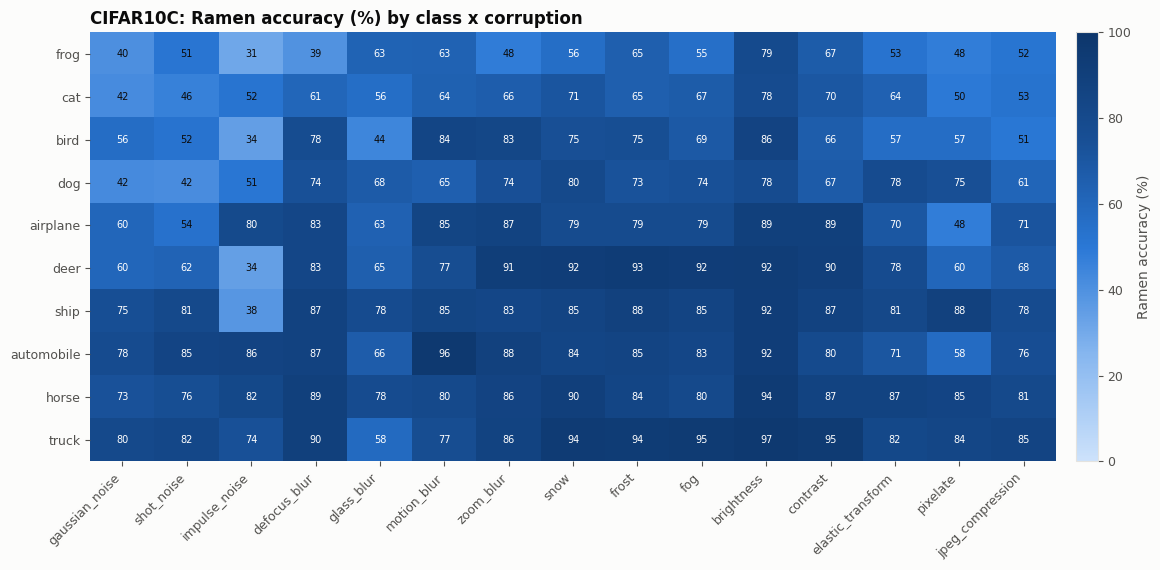

In [7]:
exp.plot_class_heatmap('Ramen');

## 4. Prediction bias / class collapse
Predicted share of each class minus its true share. Entropy-driven TTA tends to collapse onto a few "attractor" classes, which show up as large positive bars for Ramen.

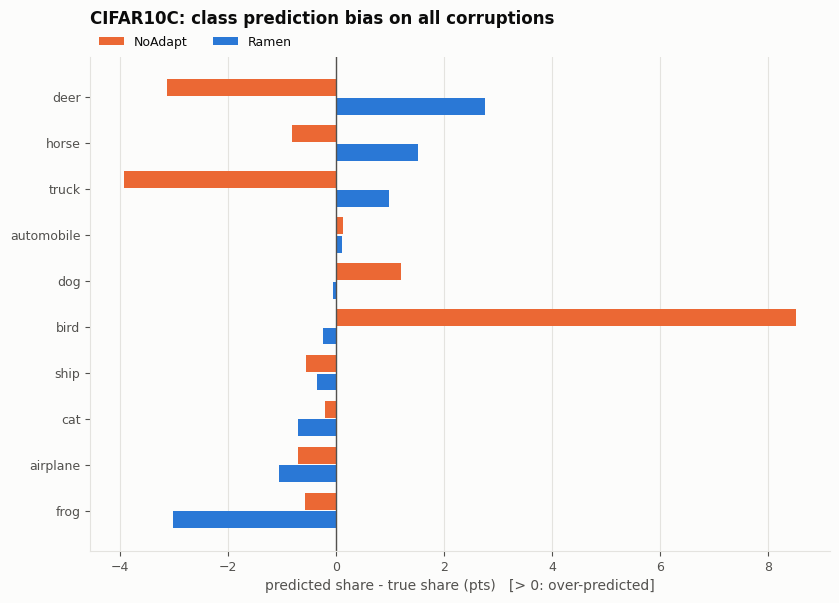

In [8]:
exp.plot_prediction_bias();

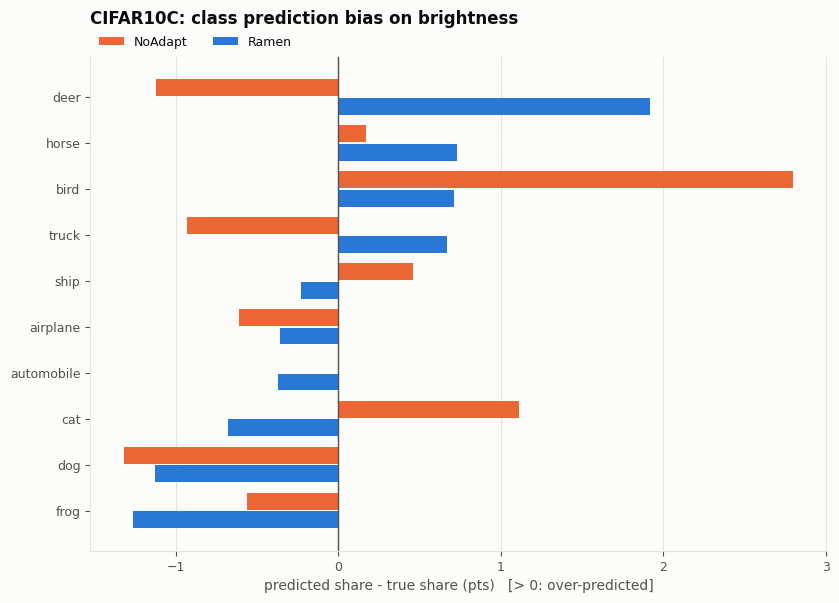

In [9]:
exp.plot_prediction_bias(domain=acc.drop('average')['delta'].idxmin());  # the corruption where Ramen gains least

## 5. What gets confused with what
The diagonal (italic) is per-class accuracy. Colour shows only the off-diagonal errors, so the confusions stand out.

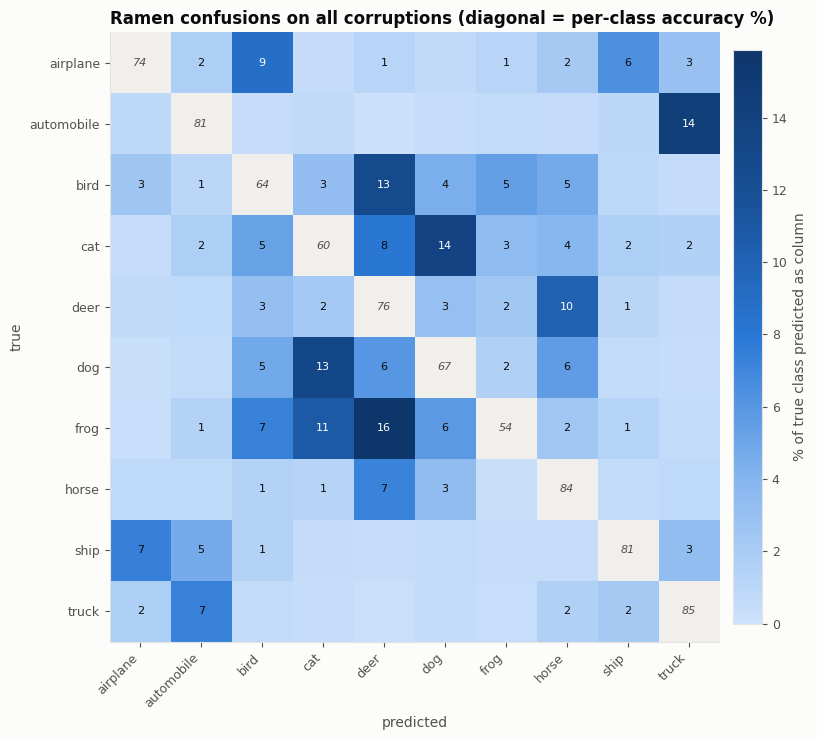

In [10]:
exp.plot_confusion();

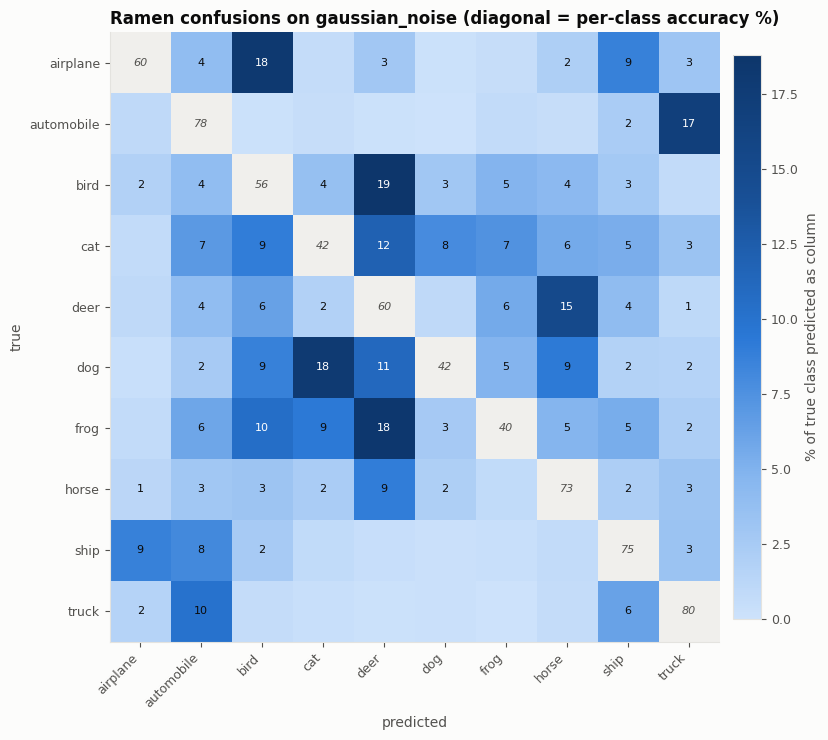

In [11]:
exp.plot_confusion(domain='gaussian_noise');

Share of errors that stay within *animal* or *vehicle* (e.g. cat → dog, not cat → truck).

In [12]:
exp.error_granularity()

,NoAdapt % errors within superclass,Ramen % errors within superclass
gaussian_noise,70.6,75.1
shot_noise,70.4,75.3
impulse_noise,77.0,83.0
defocus_blur,85.4,87.1
glass_blur,64.0,77.8
motion_blur,85.0,84.4
zoom_blur,86.0,88.1
snow,83.4,86.8
frost,84.3,86.0
fog,86.5,88.4


## 6. Does Ramen degrade over time?
Top panel: rolling accuracy along the stream. Bottom panel: rolling Ramen − NoAdapt gap. A gap that shrinks or turns red later in the stream points to cache staleness or error accumulation. In `single` mode the model is reset at each dashed line.

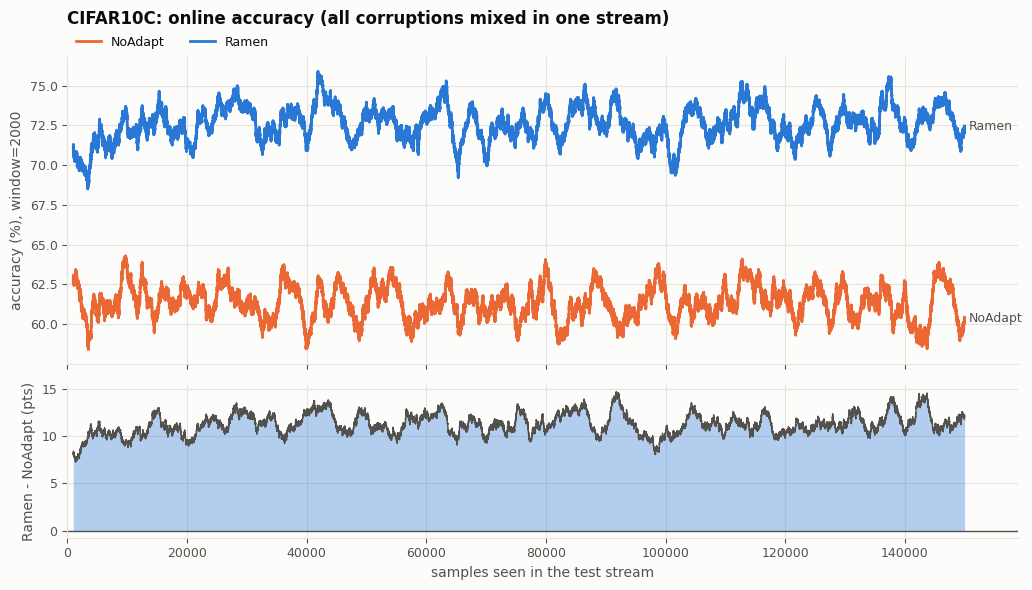

In [13]:
exp.plot_online_accuracy();

## 7. Calibration
Left: points below the diagonal mean the model is overconfident. Right: Ramen's confidence on wrong predictions. Errors made at high confidence are the most dangerous failures, because a confidence threshold won't catch them.

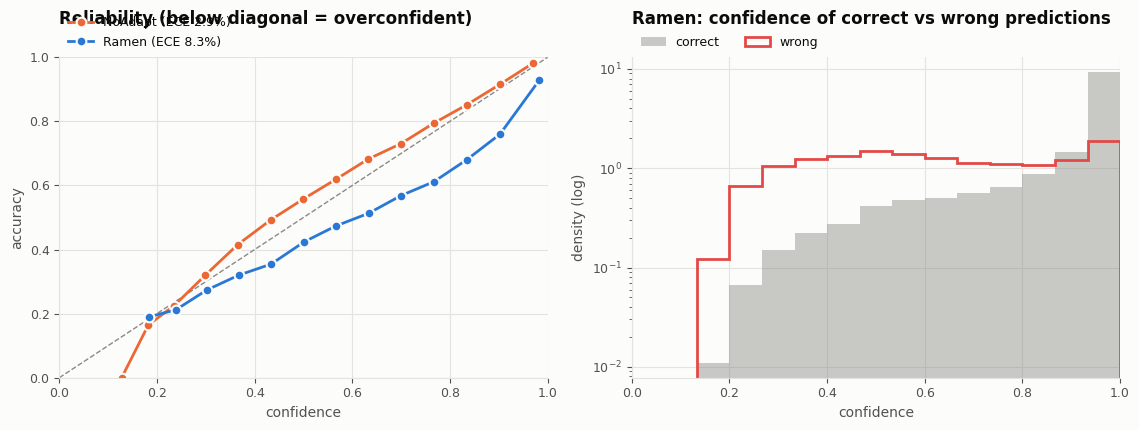

In [14]:
exp.plot_calibration();

## 8. Look at the failures
Images are sorted most-confident first. Captions show the corruption, the true class, and Ramen's prediction with its confidence.
`kind`: `'broken'` (Ramen broke a correct zero-shot prediction), `'both wrong'`, `'fixed'`, or `'wrong'` (any Ramen error).

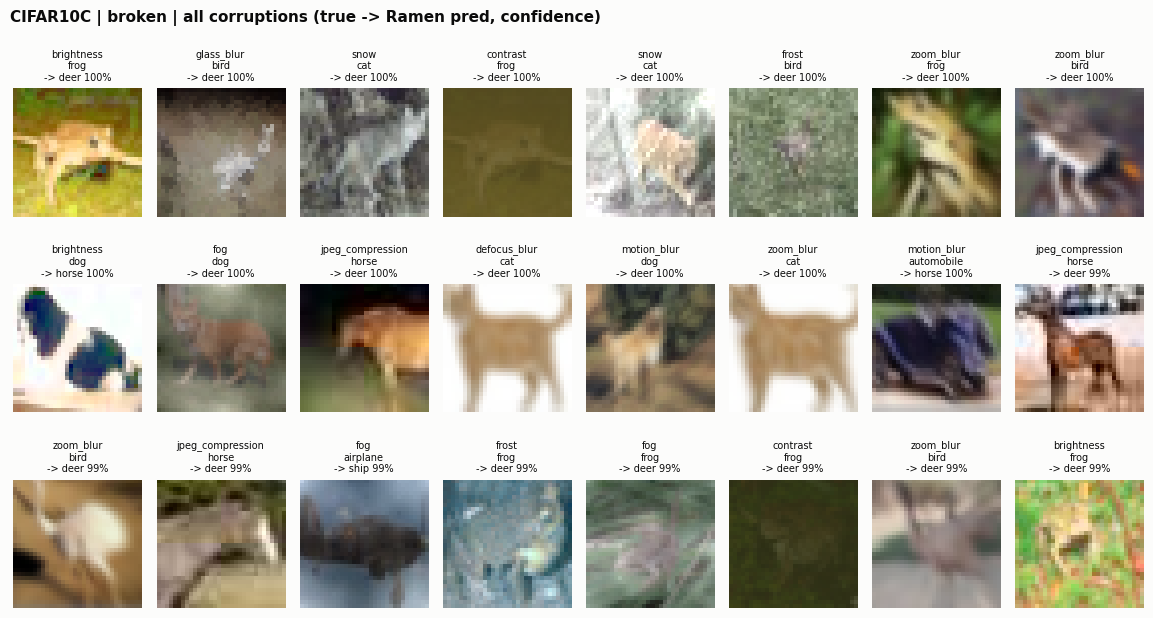

In [15]:
exp.show_failures(kind='broken', n=24);

worst corruption for Ramen: impulse_noise


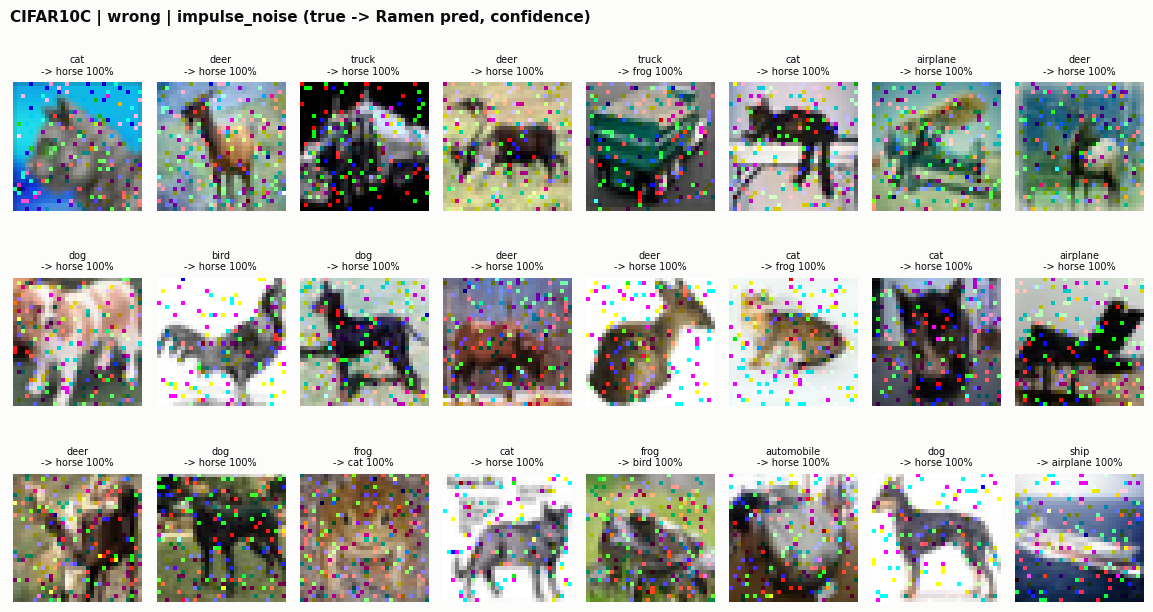

In [16]:
worst = acc.drop('average')['Ramen'].idxmin()
print('worst corruption for Ramen:', worst)
exp.show_failures(domain=worst, kind='wrong', n=24);

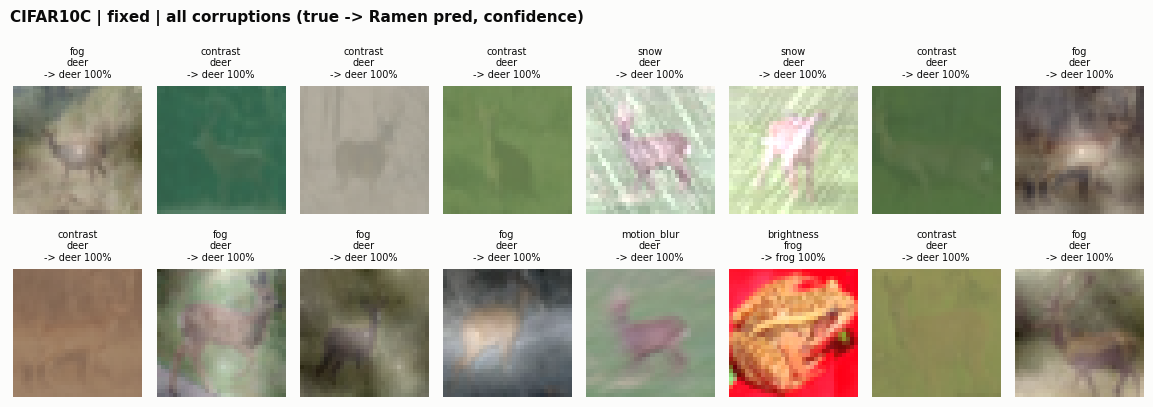

In [17]:
exp.show_failures(kind='fixed', n=16);

Images for the most confused pairs, one row per pair. A row labelled `true: A / Ramen: B` shows images whose true class is A that Ramen predicts as B. Each caption gives the corruption, Ramen's confidence in B, and what NoAdapt did on the same image: `right` (it predicted A), `same error` (it also predicted B), or the other wrong class it picked.
`order='confident'` shows the errors Ramen is surest about first; `order='borderline'` shows the ones where it barely picked B (low confidence, so other classes were close behind).

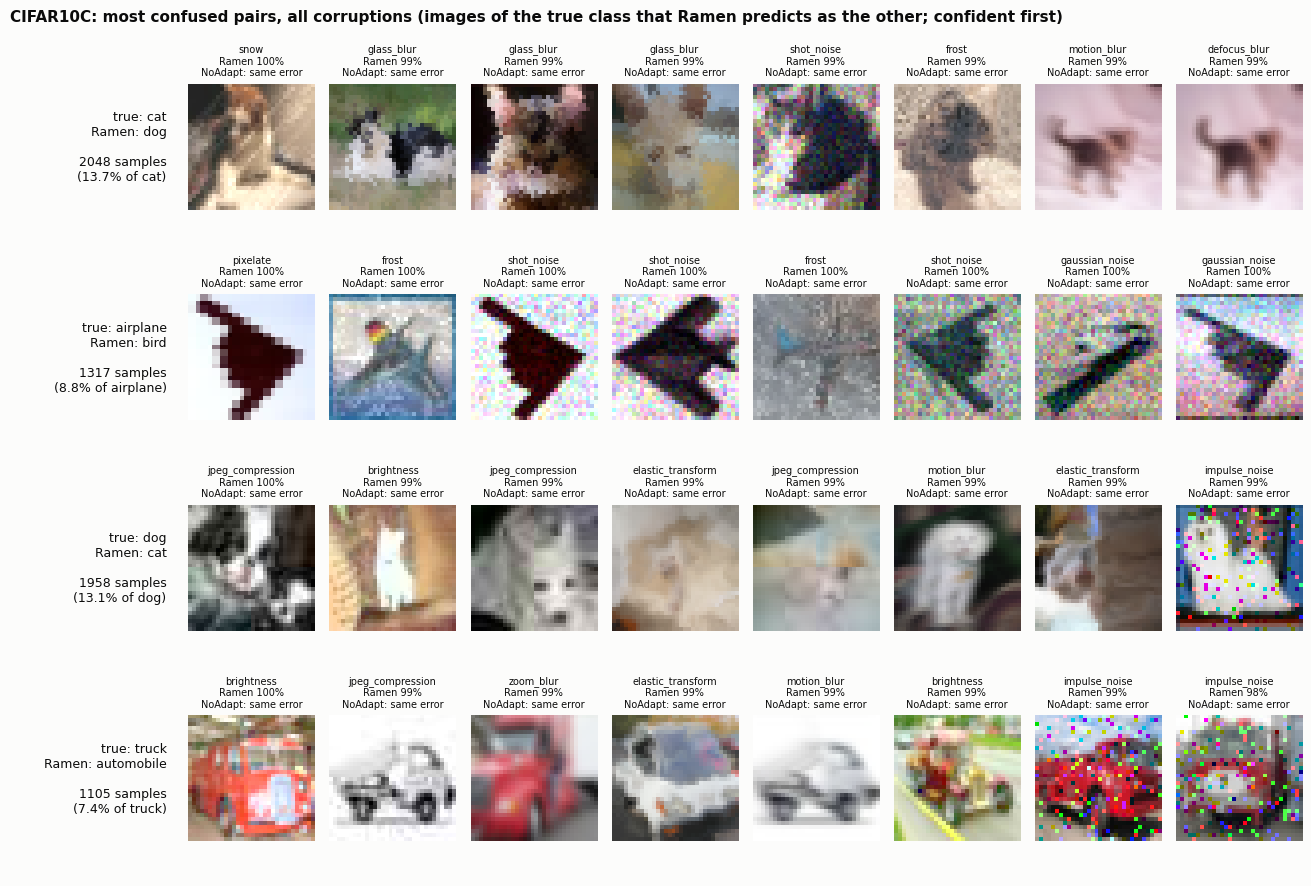

In [18]:
exp.show_confused_pairs(top_k=4, n=8);

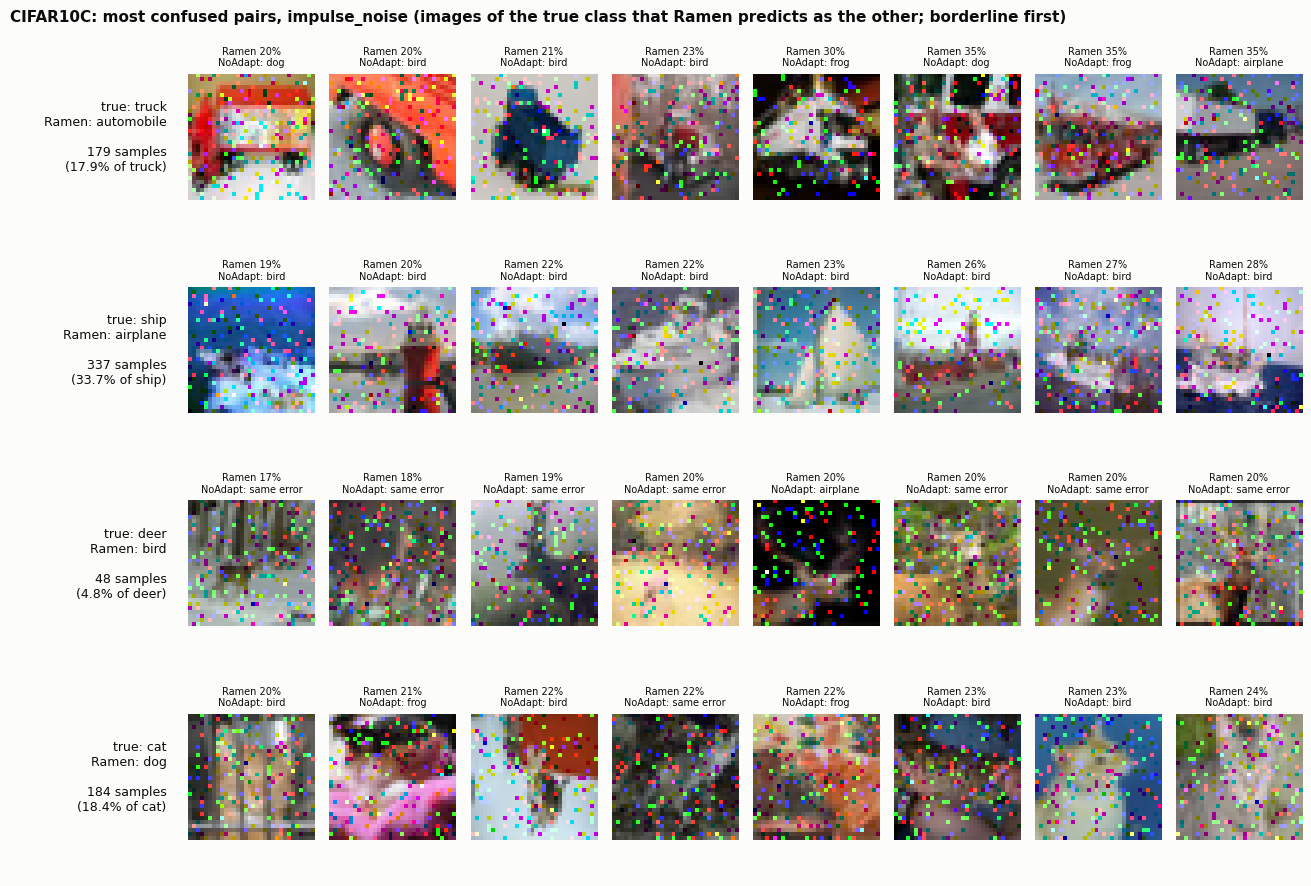

In [19]:
exp.show_confused_pairs(domain=worst, top_k=4, n=8, order='borderline');

## 9. Would "keep zero-shot when it is confident" help?
Post-hoc gate: use NoAdapt's prediction wherever its confidence is at least `tau`, and Ramen's elsewhere. This is exact for a gate that only skips a sample's own update, because the memory doesn't change. `oracle` is the ceiling for *any* per-sample choice between the two methods.

In [20]:
gate = exp.gate_sweep()
print(f"Ramen: {gate.attrs['Ramen']:.2f}   oracle (either right): {gate.attrs['oracle']:.2f}")
gate

Ramen: 72.61   oracle (either right): 78.28


,gated %,NoAdapt acc in gate,Ramen acc in gate,gated total acc,broken saved,fixed lost
tau,,,,,,
0.50,55.04,83.23,86.01,71.08,1986,4283
0.60,46.41,87.50,88.83,71.99,1111,2041
0.70,38.99,90.98,91.48,72.42,625,914
0.80,31.64,93.99,94.00,72.61,359,366
0.90,22.10,97.15,96.89,72.67,170,83
0.95,14.25,98.73,98.43,72.65,83,19
0.99,2.50,99.57,99.39,72.62,7,0


## 10. Would "don't adapt when zero-shot entropy is already low" help?
Same post-hoc gate as section 9, but the signal is zero-shot **entropy** instead of confidence: use NoAdapt's prediction wherever its entropy is at most `tau · ln C`, and Ramen's elsewhere. `ln C` is the largest possible entropy (all classes equally likely), so `tau` is a fraction of it and the same `tau` values work for any number of classes. `entropy threshold` is the cut-off in nats (`ln 10 ≈ 2.30` here). Low `tau` gates only the samples zero-shot is very sure about. (EATA uses the same scale, `0.4 · ln C`, for the opposite rule: it skips *high*-entropy samples.)
The columns mean the same as in section 9:
- `gated %`: share of samples kept at zero-shot.
- `broken saved`: gated samples where Ramen was wrong and zero-shot right.
- `fixed lost`: gated samples where Ramen was right and zero-shot wrong.
- Compare `gated total acc` with Ramen's accuracy printed above the table.

In [21]:
entropy_gate = exp.entropy_gate_sweep()   # taus=(0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6) by default
print(f"Ramen: {entropy_gate.attrs['Ramen']:.2f}   oracle (either right): {entropy_gate.attrs['oracle']:.2f}")
entropy_gate

Ramen: 72.61   oracle (either right): 78.28


,entropy threshold,gated %,NoAdapt acc in gate,Ramen acc in gate,gated total acc,broken saved,fixed lost
tau,,,,,,,
0.05,0.115,5.40,99.48,99.14,72.63,29,1
0.10,0.230,12.41,98.92,98.60,72.65,72,13
0.20,0.461,22.45,96.89,96.66,72.66,178,101
0.30,0.691,30.28,94.20,94.19,72.61,342,340
0.40,0.921,38.29,90.33,91.15,72.30,798,1270
0.50,1.151,45.52,86.87,88.75,71.75,1326,2614
0.60,1.382,53.00,83.38,86.36,71.03,1958,4329
